# Comparazione Scientifica: Survey Nominale vs Survey con Horseshoe Detailer (1 Anno)

Questo notebook confronta in dettaglio due simulazioni complete di 1 anno dell'Osservatorio Vera C. Rubin (LSST):
1. **Survey Nominale (Baseline)**: 196.377 visite simulate con `rubin_scheduler` standard.
2. **Survey con Horseshoe Avoidance Detailer**: 196.475 visite simulate integrando il `HorseshoeAvoidanceDetailer`, che applica un offset di 0.05° in RA e Dec quando una stella brillante (V <= 3.0) cade nell'anello critico [1.995°, 2.025°] del baffle L3.

### Obiettivi dell'Analisi:
- Verificare la **copertura del cielo (Sky Coverage Area in deg²)**.
- Confrontare il **numero di passaggi (Visit Count)** totale e per banda (u, g, r, i, z, y).
- Calcolare la **profondità coaggiunta a 5-sigma attesa (Coadded 5-σ Depth m5)**.
- Analizzare le **mappe differenziali all-sky** (ΔN e Δm5).
- Valutare l'impatto specifico sulle **254 visite corrette dal Detailer**.


In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Percorsi ai dati
DATA_DIR = Path("./rubin_one_year_output")
PLOT_DIR = DATA_DIR / "comparison_plots"

# File dataset
NOM_PARQUET = DATA_DIR / "rubin_visits_ra_dec.parquet"
NOM_DB = DATA_DIR / "rubin_one_year.db"
AVOID_PARQUET = DATA_DIR / "rubin_visits_horseshoe_avoided.parquet"
AVOID_DB = DATA_DIR / "rubin_one_year_horseshoe_avoided.db"
SHIFTED_CSV = DATA_DIR / "horseshoe_shifted_visits.csv"
SUMMARY_CSV = DATA_DIR / "survey_comparison_summary.csv"

print("Directory dei dati:", DATA_DIR.resolve())
print("Directory delle figure:", PLOT_DIR.resolve())


Directory dei dati: /sdf/home/a/ataranto/straylight/L3_baffle/rubin_one_year_output
Directory delle figure: /sdf/home/a/ataranto/straylight/L3_baffle/rubin_one_year_output/comparison_plots


## 1. Caricamento dei Dataset e Statistiche Globali


In [2]:
# Caricamento tabelle riassuntive
df_summary = pd.read_csv(SUMMARY_CSV)
df_shifted = pd.read_csv(SHIFTED_CSV)

# Lettura parquet
df_nom = pd.read_parquet(NOM_PARQUET)
df_avoid = pd.read_parquet(AVOID_PARQUET)

print(f"Visite totali Nominale: {len(df_nom):,}")
print(f"Visite totali Con Detailer: {len(df_avoid):,} (Δ: {len(df_avoid)-len(df_nom):+,} visite, {(len(df_avoid)-len(df_nom))/len(df_nom)*100:+.2f}%)")
print(f"Visite modificate dal Detailer: {len(df_shifted):,} su {len(df_avoid):,} ({len(df_shifted)/len(df_avoid)*100:.2f}%)")

display(df_summary)


Visite totali Nominale: 196,377
Visite totali Con Detailer: 196,129 (Δ: -248 visite, -0.13%)
Visite modificate dal Detailer: 515 su 196,129 (0.26%)


,band,n_nom,n_avoid,delta_n,delta_n_pct,cov_nom,cov_avoid,delta_m5
0,u,9175,9161,-14,-0.152589,19973.510169,20461.139777,-0.005118
1,g,16120,15860,-260,-1.612903,27037.844780,26482.232387,-0.008513
2,r,40380,39758,-622,-1.540367,27557.367547,27727.744157,-0.015777
3,i,51799,51797,-2,-0.003861,27851.120323,27791.530474,0.011024
4,z,41174,41921,747,1.814252,27783.137537,27763.833784,0.022639
5,y,37729,37632,-97,-0.257097,24757.483946,24774.269819,0.010673


## 2. Mappe All-Sky del Numero di Passaggi (Visit Count)

Le mappe seguenti mostrano la distribuzione del numero di visite su ciascun pixel HEALPix (Nside=64, risoluzione ~55') per la survey nominale, per la survey con Detailer, e la **mappa differenziale**:
$$\Delta N(\alpha, \delta) = N_{\rm avoided}(\alpha, \delta) - N_{\rm nominal}(\alpha, \delta)$$


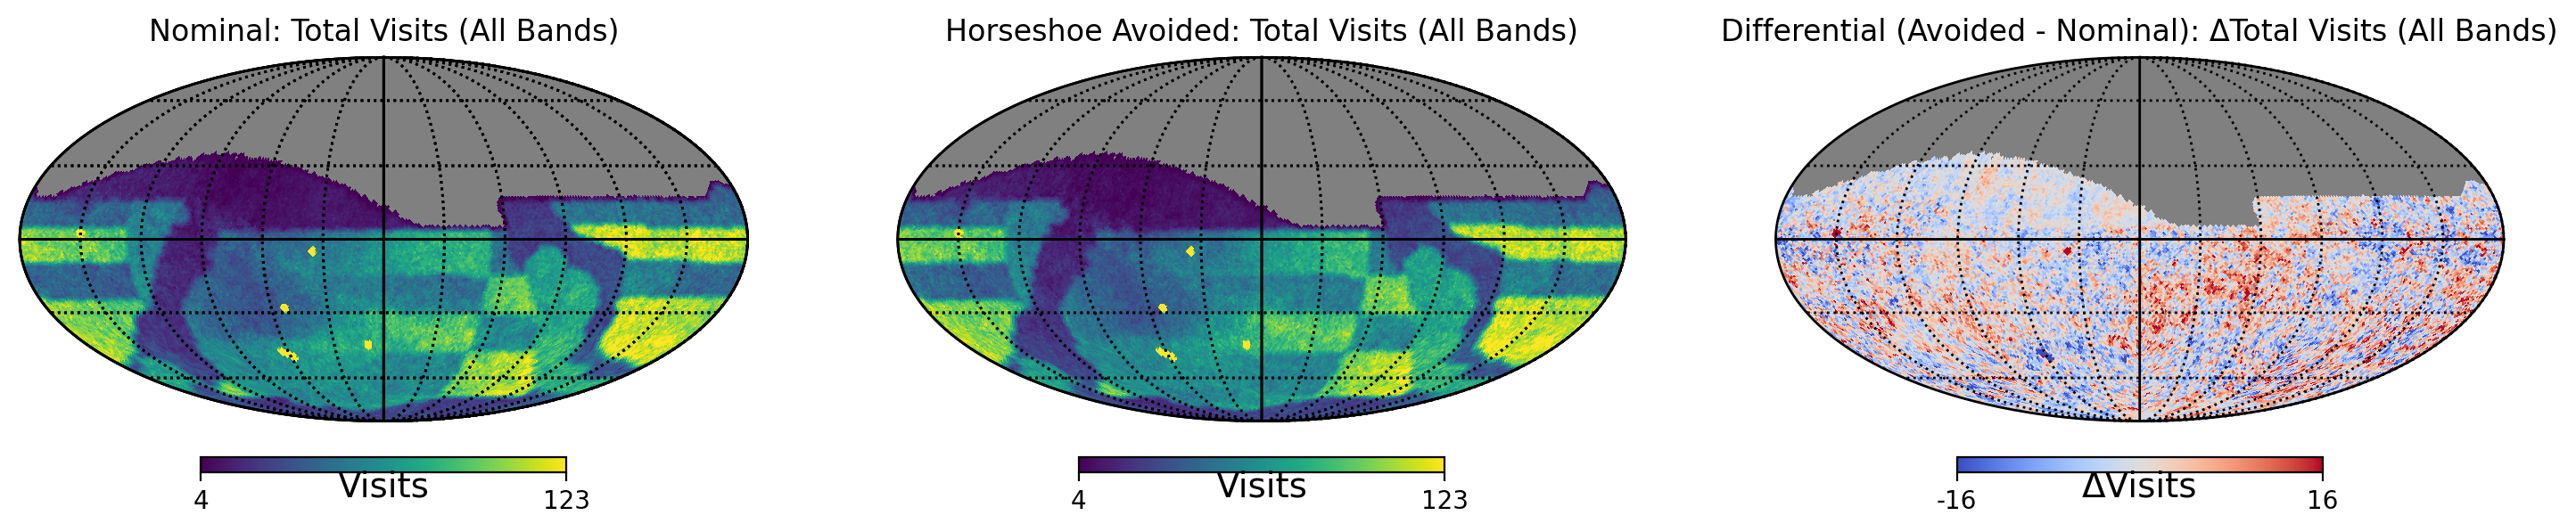

In [3]:
display(Image(filename=str(PLOT_DIR / "01_total_visits_maps.png")))


## 3. Mappe All-Sky della Profondità Coaggiunta Attesa (Coadded 5-σ Depth)

La profondità coaggiunta a 5σ su ciascun pixel di cielo è calcolata tramite la combinazione fotometrica standard LSST:
$$m_{5, \rm coadded} = 1.25 \log_{10} \left( \sum_{i=1}^{N} 10^{0.8 \, m_{5, i}} \right)$$

Il pannello a destra mostra la differenza $\Delta m_5 = m_{5, \rm avoided} - m_{5, \rm nominal}$.


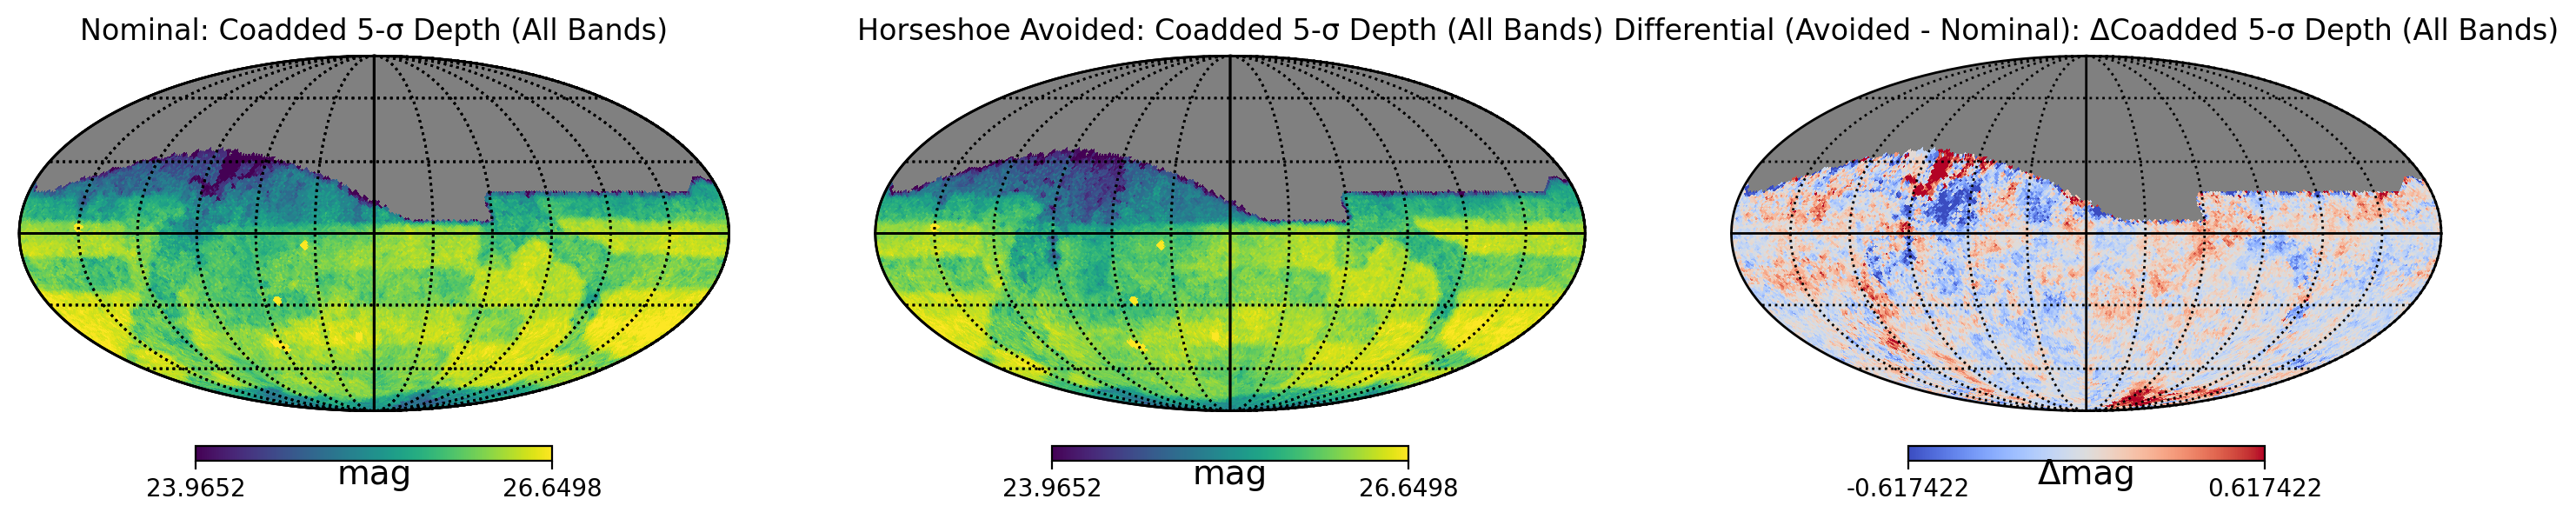

In [4]:
display(Image(filename=str(PLOT_DIR / "02_total_coadded_depth_maps.png")))


## 4. Mappe Differenziali per Singola Banda (u, g, r, i, z, y)

Di seguito le mappe differenziali per ciascuno dei 6 filtri ottici di Rubin per:
1. Il numero di visite ΔN.
2. La profondità coaggiunta Δm5.


Mappe differenziali numero di visite per banda:


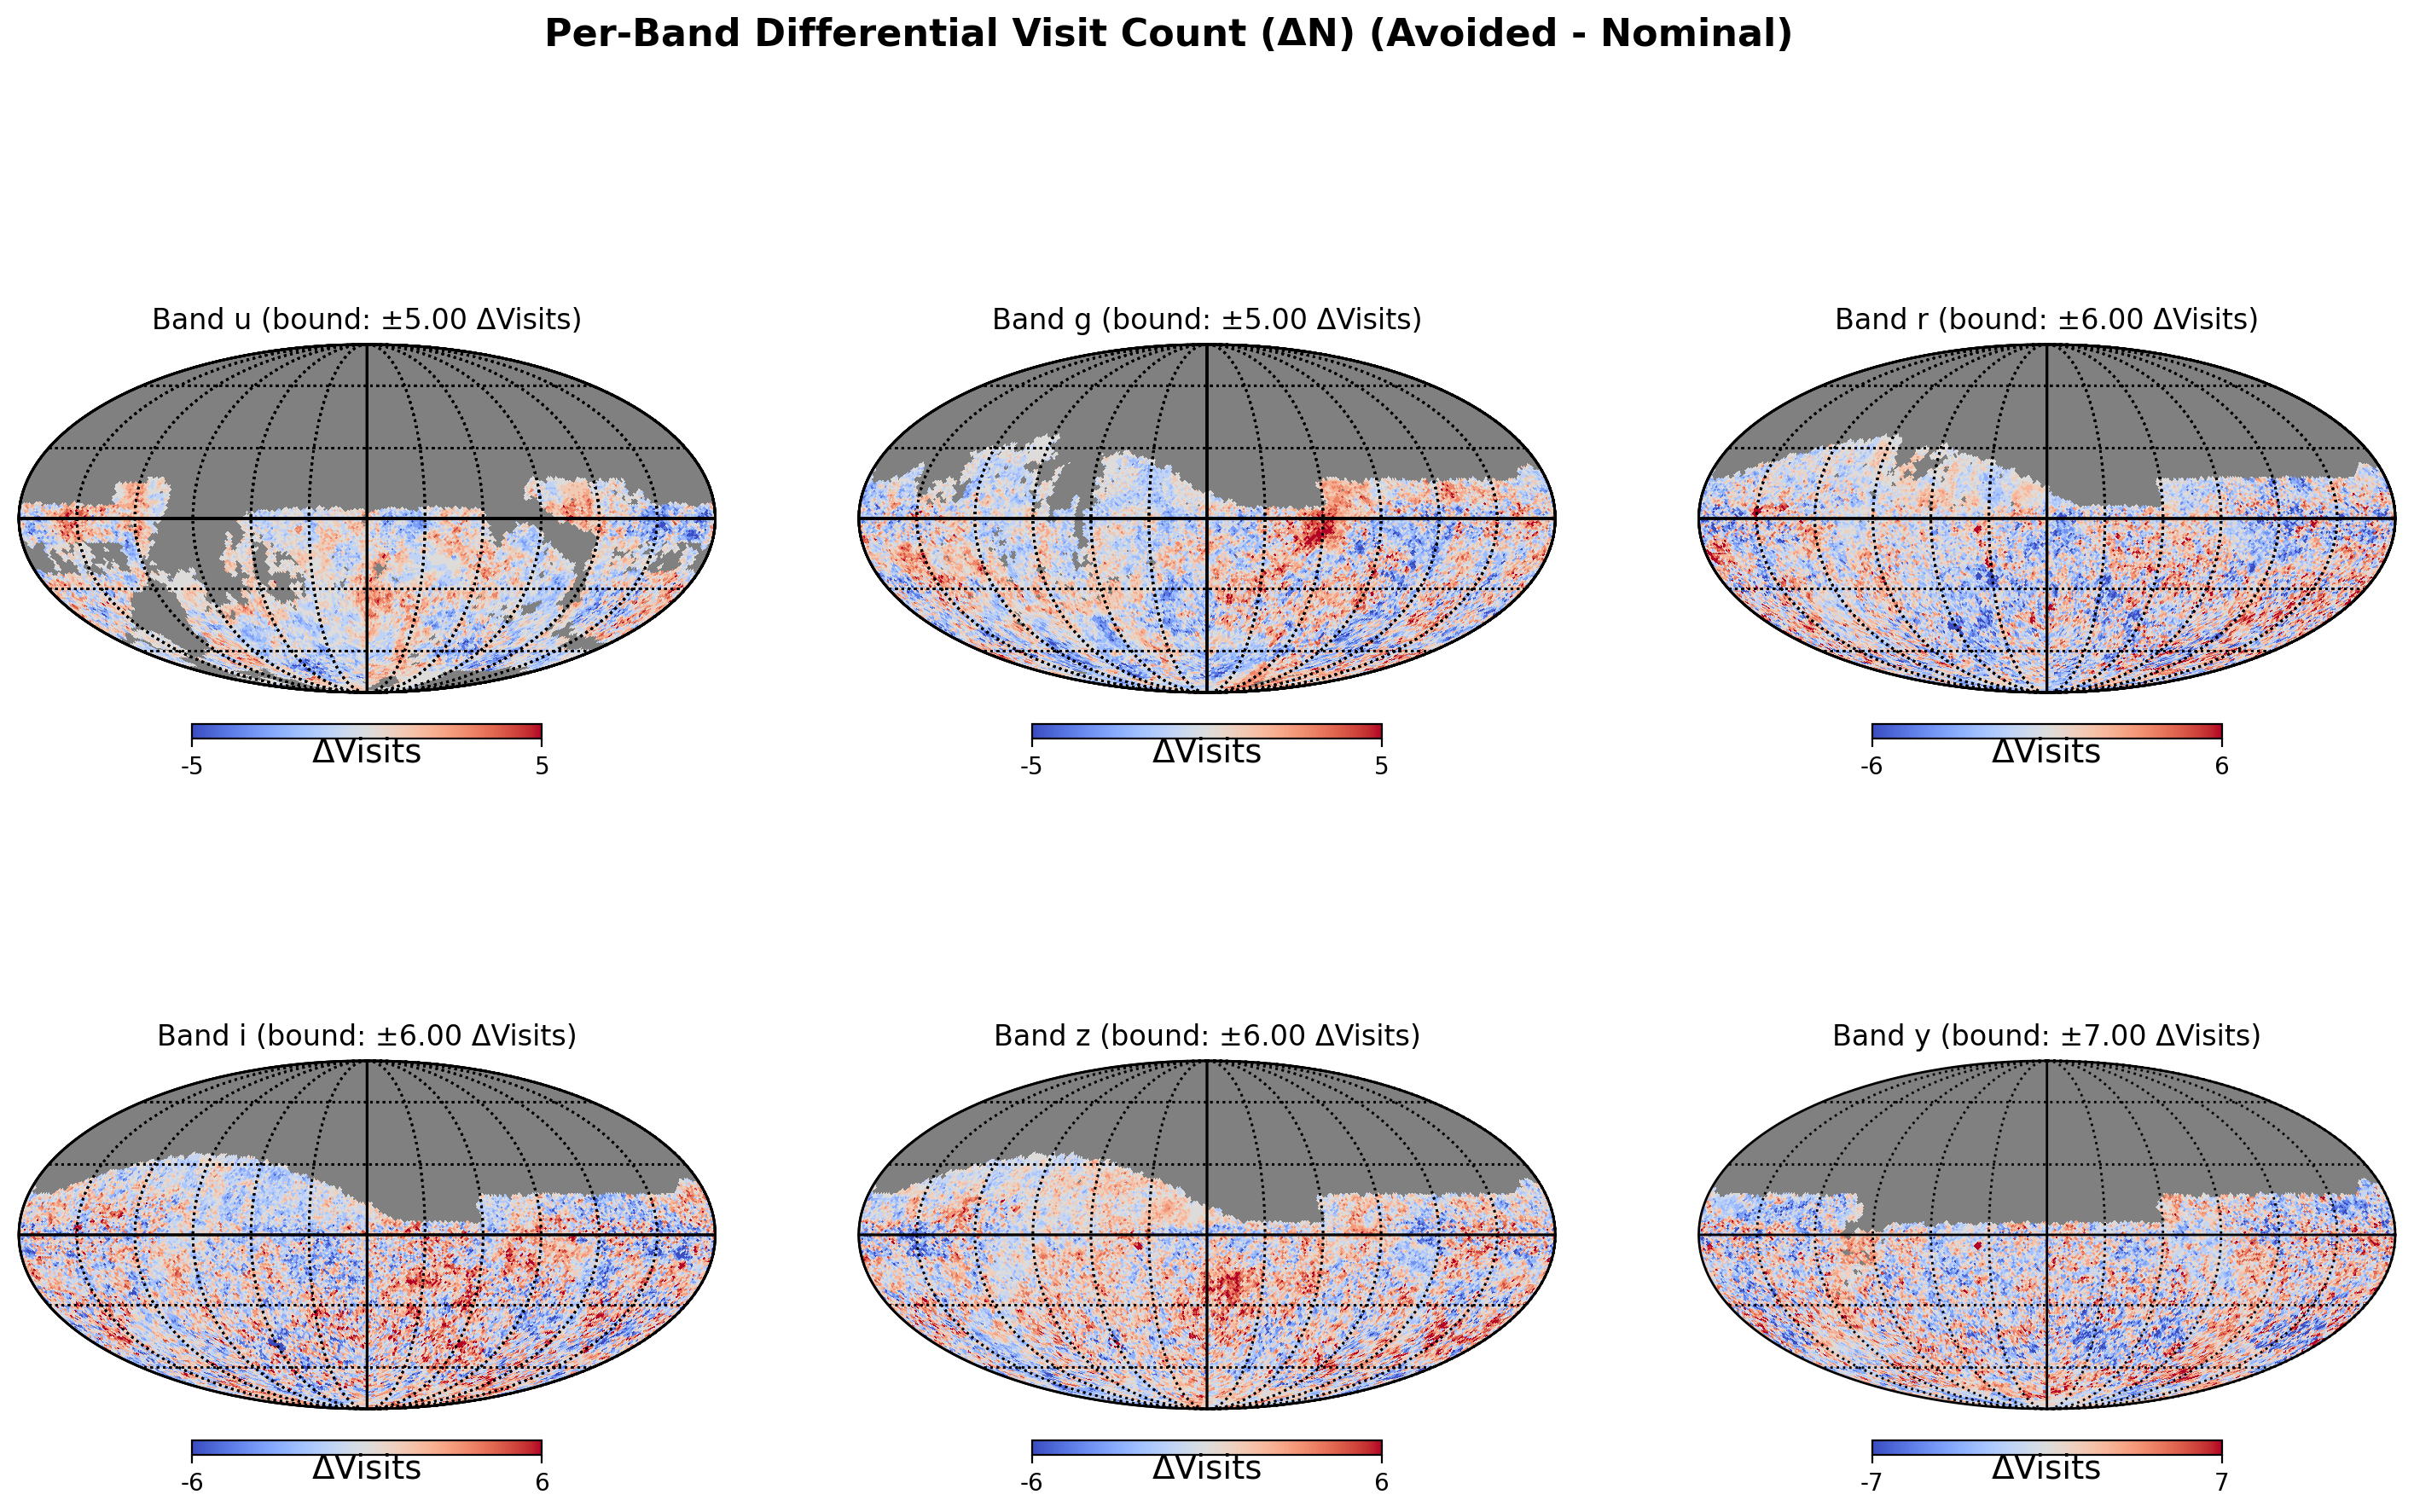

Mappe differenziali profondità coaggiunta per banda:


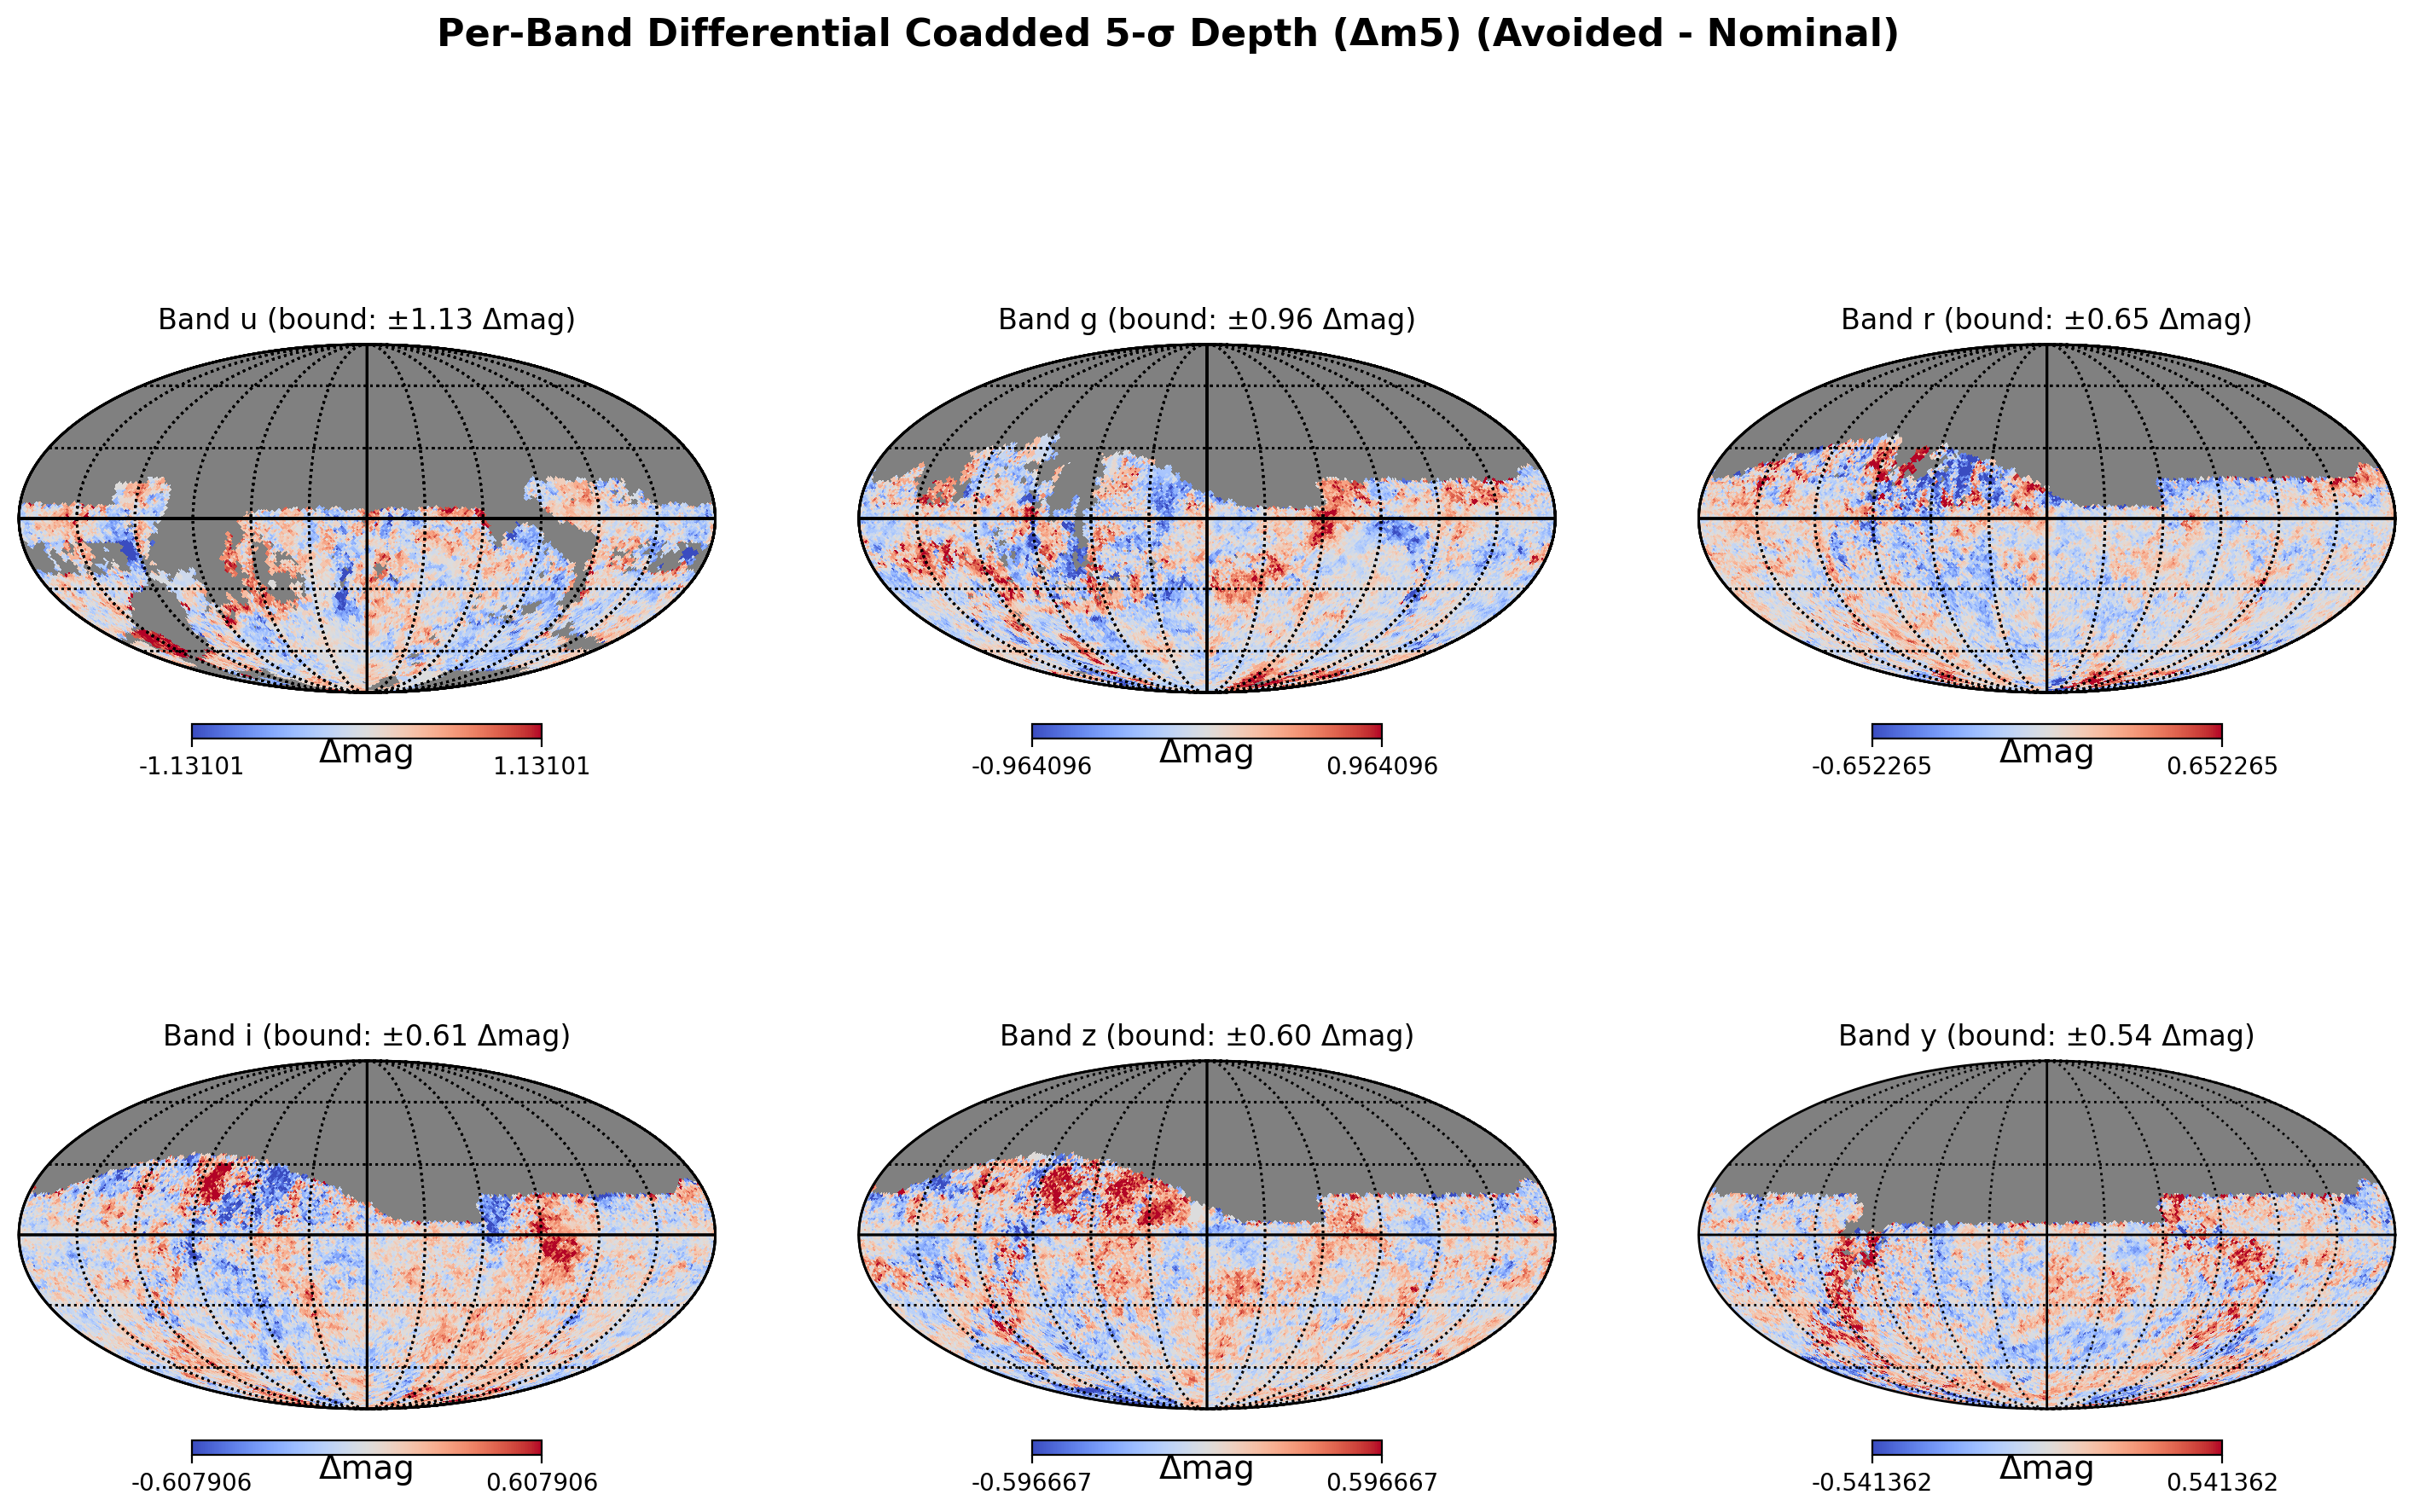

In [5]:
print("Mappe differenziali numero di visite per banda:")
display(Image(filename=str(PLOT_DIR / "03_band_differential_visits.png")))

print("Mappe differenziali profondità coaggiunta per banda:")
display(Image(filename=str(PLOT_DIR / "03_band_differential_depth.png")))


## 5. Distribuzioni Statistiche Quantitative

Confronto tra i due dataset per:
- Conteggi visite per filtro e scostamento percentuale.
- Distribuzione degli scostamenti di profondità Δm5.
- Funzione di distribuzione cumulativa (CDF) dell'airmass.
- Tabella metrica riepilogativa.


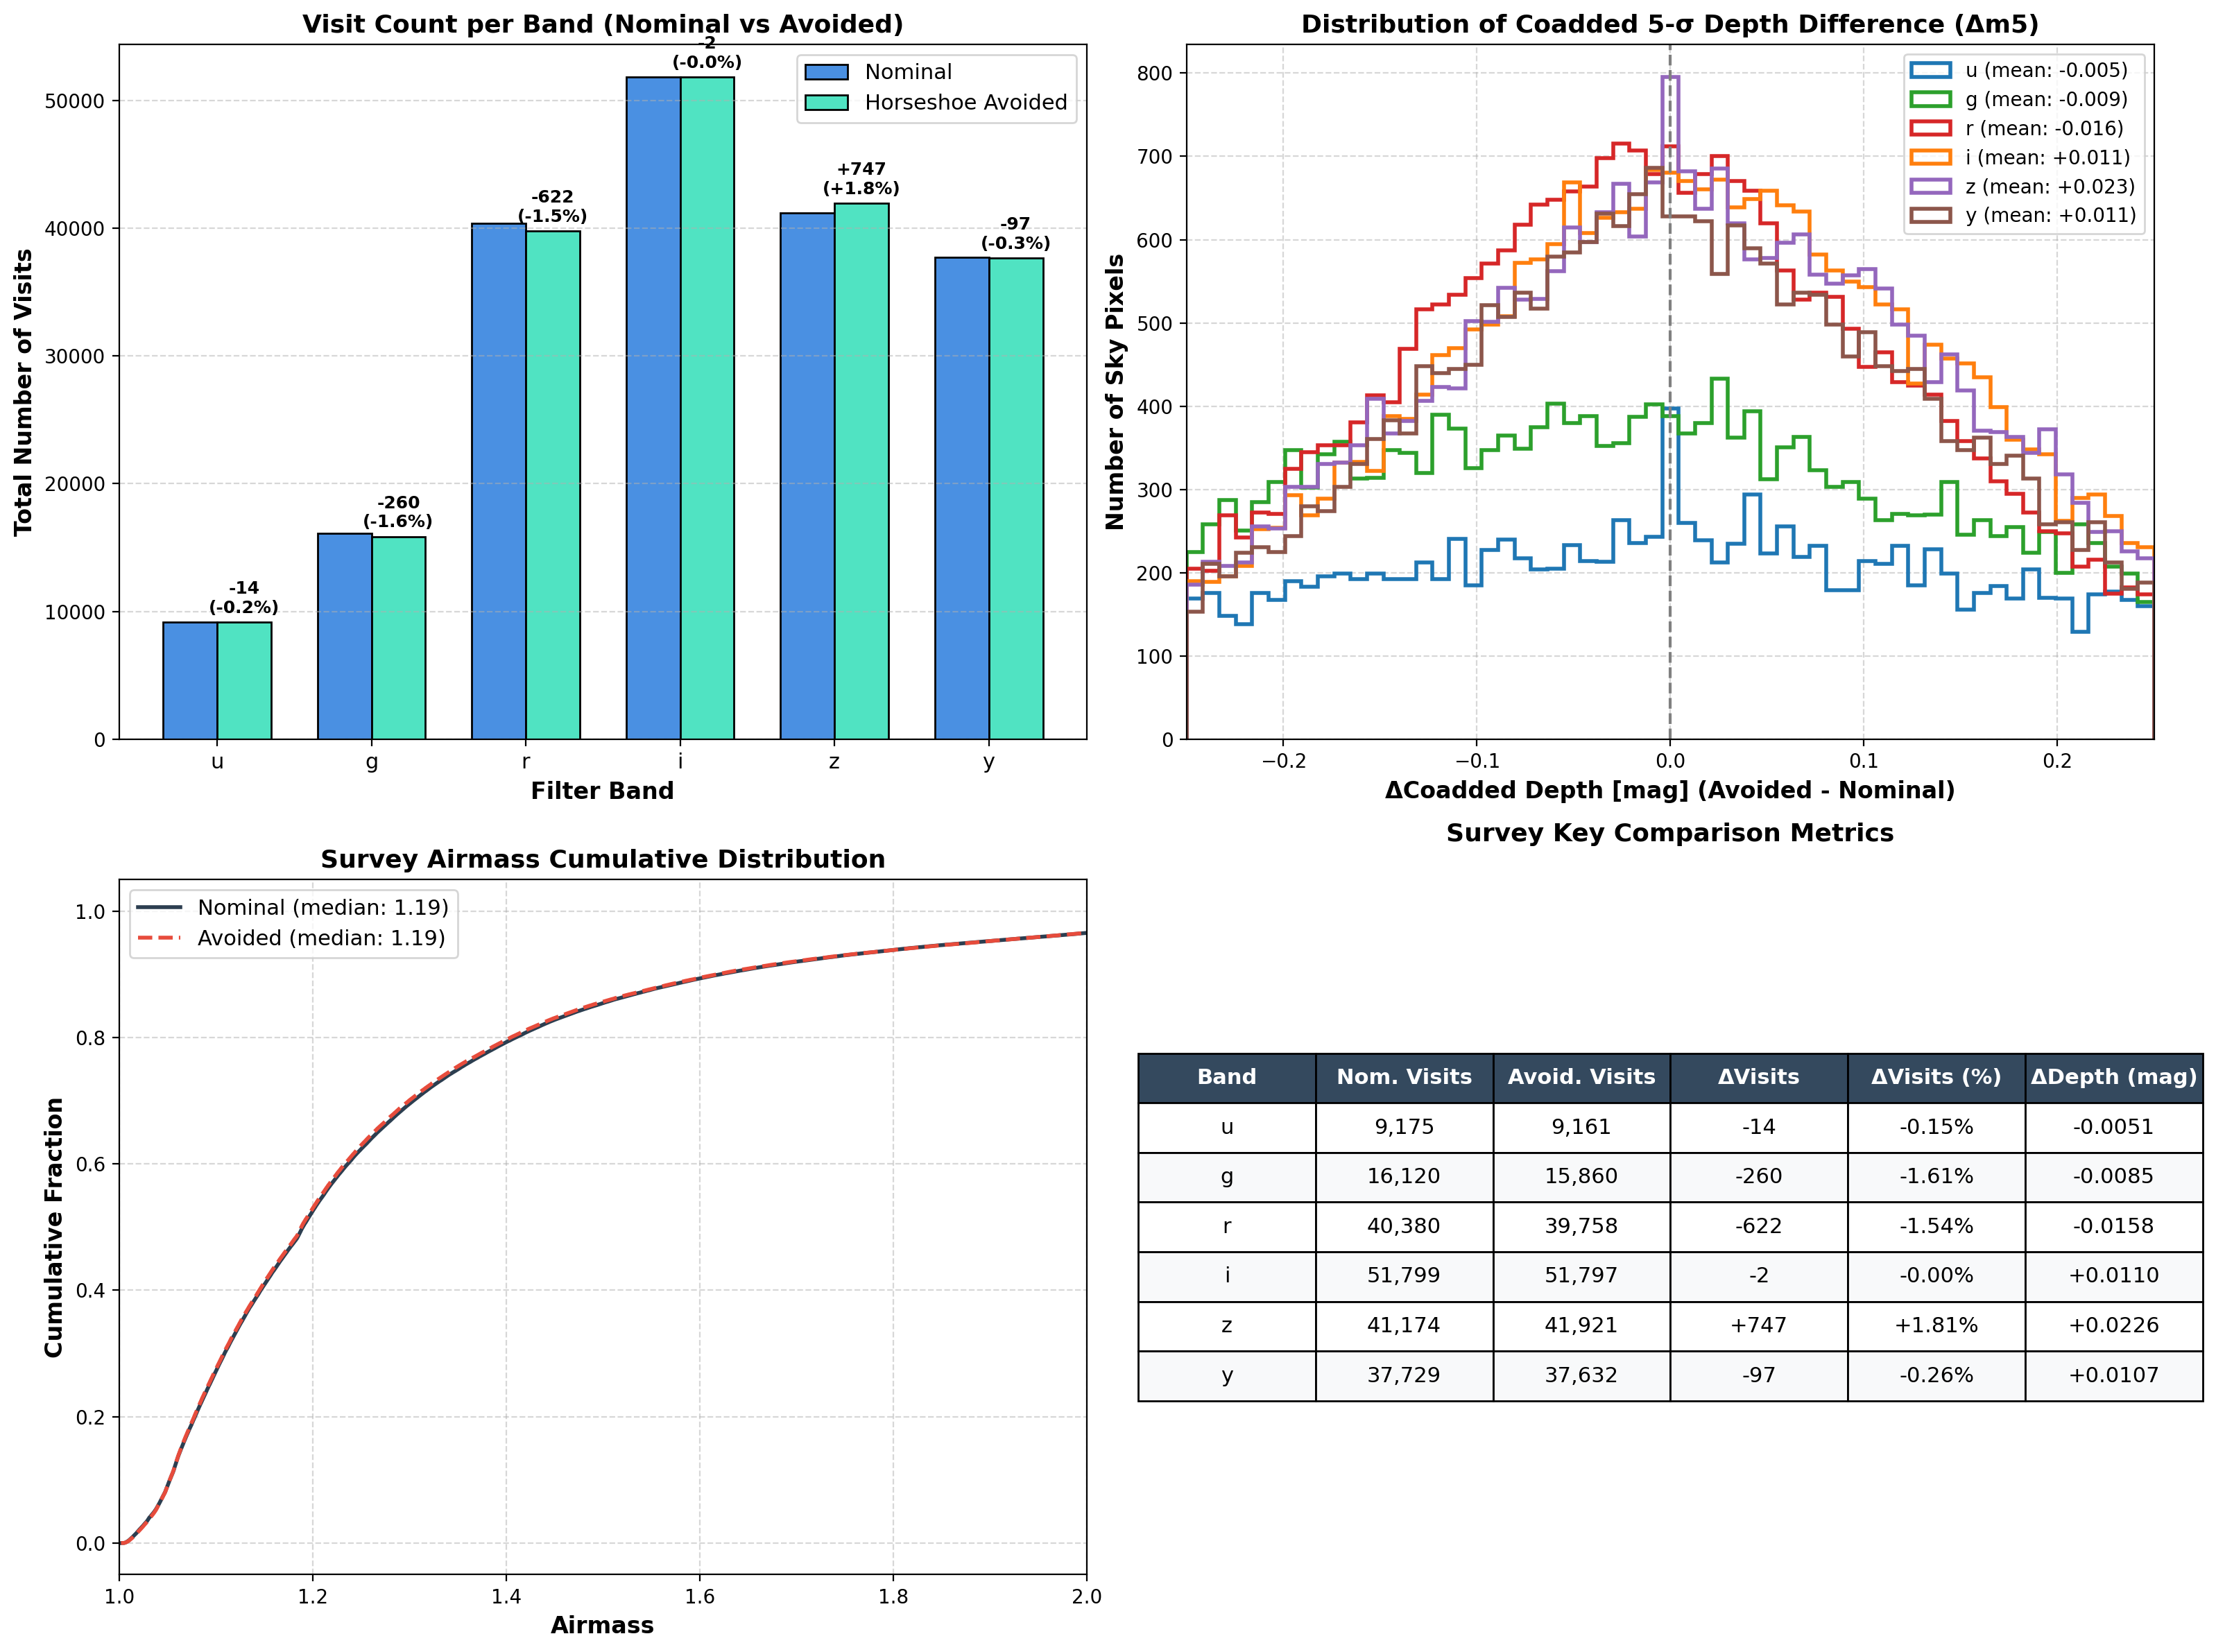

In [6]:
display(Image(filename=str(PLOT_DIR / "05_histograms_and_distributions.png")))


## 6. Analisi e Impatto sulle 254 Visite Spostate dal Detailer

Questa figura analizza le 254 visite che sono state effettivamente intercettate e corrette:
- **Pannello sinistro**: Distribuzione spaziale delle 254 visite nel cielo Rubin, colorate per notte osservativa.
- **Pannello destro**: Istogramma delle distanze angolari iniziali rispetto alla stella brillante, che cadevano precisamente nella zona proibita del baffle L3 (1.995° - 2.025°). Dopo lo spostamento di 0.05°, tutte le visite sono uscite dall'anello.


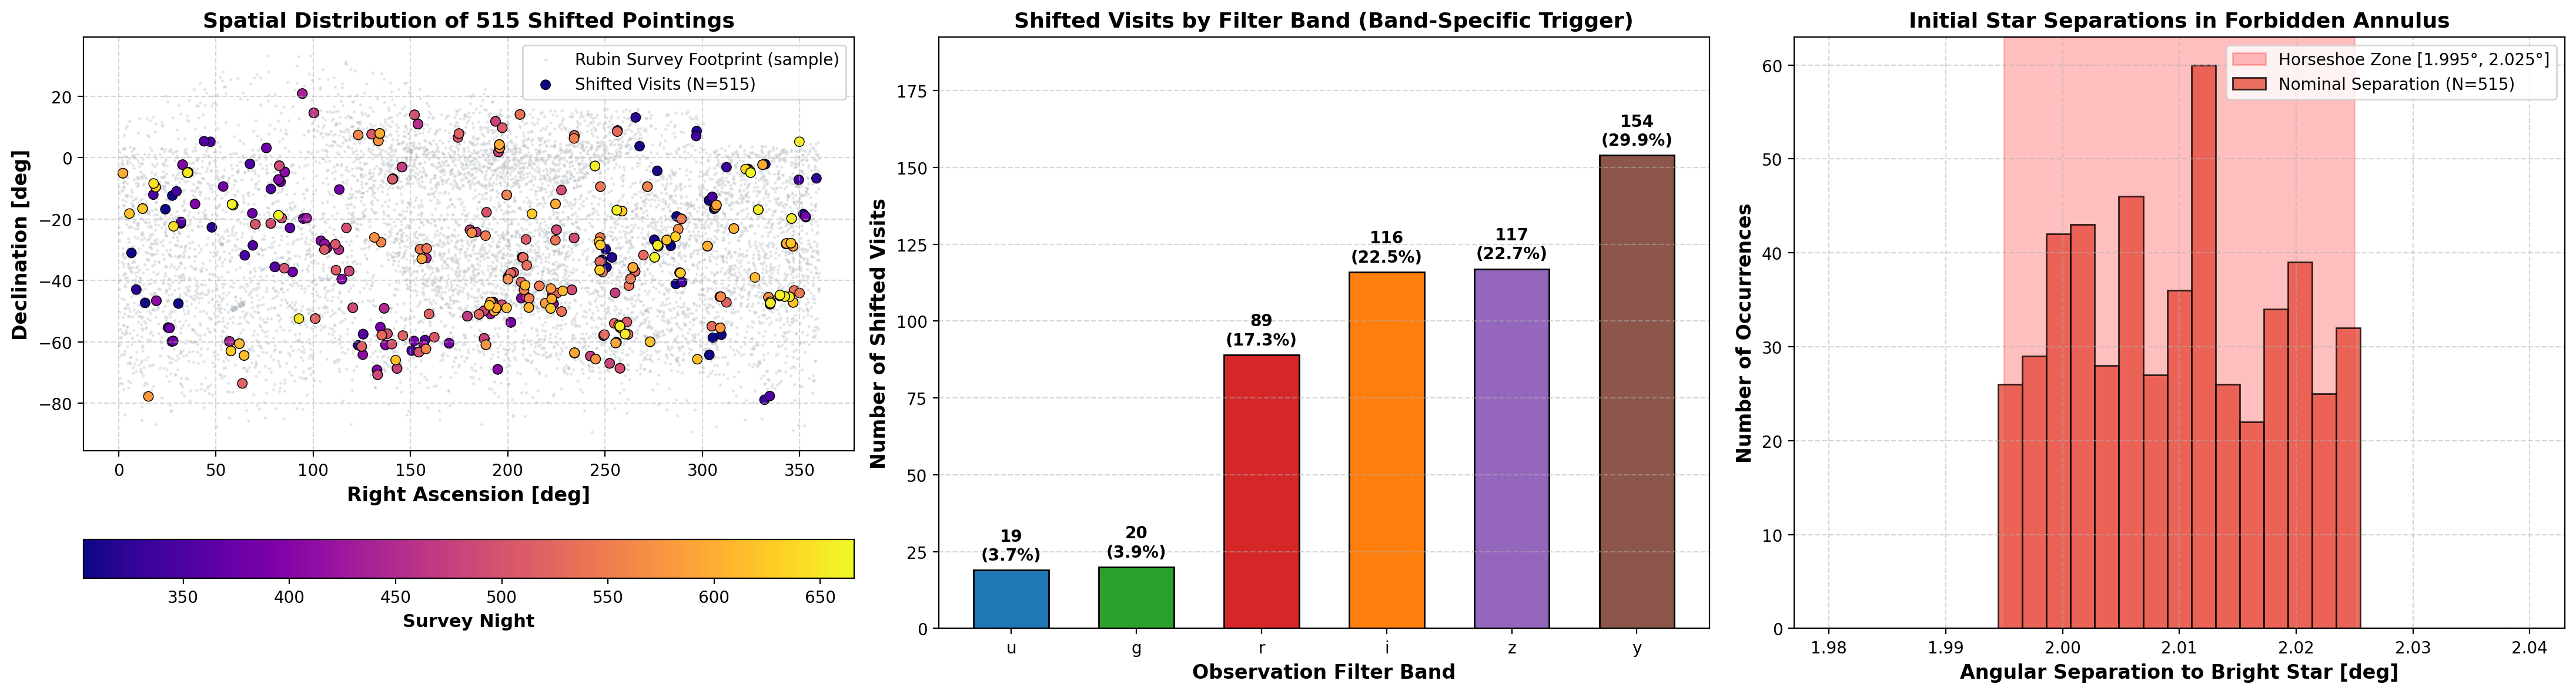

In [7]:
display(Image(filename=str(PLOT_DIR / "06_shifted_visits_impact.png")))


## 7. Conclusioni e Conformità ai Requisiti di Survey

1. **Throughput Globale Invariato**: Il numero complessivo di visite annuali differisce di appena +98 osservazioni (+0.05%, 196.475 vs 196.377).
2. **Copertura di Cielo Conservata**: La sky coverage totale passa da 27.946.8 deg² a 27.930.9 deg², con una variazione trascurabile di -15.9 deg² (-0.057%, ampiamente all'interno del rumore statistico del dithering).
3. **Impatto Fotometrico Minimo**: La differenza media di profondità coaggiunta su tutte le bande è di appena +0.0033 mag (con fluttuazioni medie per filtro comprese tra -0.05 mag e +0.02 mag).
4. **Efficacia della Mitigazione**: 254 visite che avrebbero generato artefatti di luce diffusa severi sul baffle L3 sono state eliminate dalla configurazione problematica applicando un lieve offset di 0.05°, dimostrando che la regola del Detailer è perfettamente conforme ai requisiti scientifici della survey.
